# 04 — Power Analysis (Step 5)

**What does a power analysis tell us?** It answers, *before* running an experiment: "With the users I have, how small an effect
can I detect reliably?"

- **MDE (Minimum Detectable Effect):** the smallest true effect that comes out significant with 80% probability (power) at α = 0.05.
- A smaller effect may be real, but the experiment will usually miss it.

Two questions to answer:
1. How small an effect on visit can we detect?
2. Conversion is very rare (0.2%). How many users does it need?

**Important:** the split is 85:15, so statsmodels needs `ratio = n_control / n_treatment = 0.15/0.85 ≈ 0.176`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.data import load_criteo
from src.stats_tests import mde_proportion, sample_size_proportion, itt_effect

FIG = Path.cwd().parent / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

df = load_criteo()
n_t, n_c = int(df.treatment.sum()), int((df.treatment == 0).sum())
T_SHARE = 0.85
FULL_N = 13_979_592

# Baseline = control rate (what we'd expect without ads)
base = {m: df.loc[df.treatment == 0, m].mean() for m in ["visit", "conversion"]}
observed = {m: itt_effect(df.loc[df.treatment == 1, m].values, df.loc[df.treatment == 0, m].values)["effect"]
            for m in ["visit", "conversion"]}
exposure_rate = df.loc[df.treatment == 1, "exposure"].mean()
print(f"n_treatment={n_t:,}  n_control={n_c:,}  ratio={n_c/n_t:.3f}")
print("Baseline (control) rates:", {k: f"{v:.4%}" for k, v in base.items()})

n_treatment=1,188,739  n_control=209,220  ratio=0.176
Baseline (control) rates: {'visit': '3.8185%', 'conversion': '0.1964%'}


## 5.1 Question 1: How small an effect on visit can we detect?

In [2]:
rows = []
for m in ["visit", "conversion"]:
    for label, nt, nc in [("10% sample", n_t, n_c), ("full data", int(FULL_N * T_SHARE), int(FULL_N * (1 - T_SHARE)))]:
        r = mde_proportion(base[m], nt, nc)
        rows.append({"metric": m, "data": label, "n_total": r["n_total"], "baseline": base[m],
                     "MDE_abs (pp)": r["mde_abs"] * 100, "MDE_rel": r["mde_rel"],
                     "observed ITT (pp)": observed[m] * 100,
                     "observed / MDE": observed[m] / r["mde_abs"]})
mde_tbl = pd.DataFrame(rows).set_index(["metric", "data"])
mde_tbl

n_total  baseline  MDE_abs (pp)  MDE_rel  \
metric     data                                                    
visit      10% sample   1397959   0.03818       0.12831  0.03360   
           full data   13979591   0.03818       0.04032  0.01056   
conversion 10% sample   1397959   0.00196       0.03051  0.15530   
           full data   13979591   0.00196       0.00940  0.04786   

                       observed ITT (pp)  observed / MDE  
metric     data                                           
visit      10% sample            1.06654         8.31234  
           full data             1.06654        26.45443  
conversion 10% sample            0.12314         4.03620  
           full data             0.12314        13.09828

In [3]:
v = mde_tbl.loc[("visit", "10% sample")]
c = mde_tbl.loc[("conversion", "10% sample")]
print(f"VISIT (10% sample): MDE = {v['MDE_abs (pp)']:.3f} pp ({v['MDE_rel']:.1%} relative)")
print(f"   = we can detect as few as {v['MDE_abs (pp)']*10:.2f} extra visits per 1,000 assigned users")
print(f"   Observed effect {v['observed ITT (pp)']:.2f} pp = {v['observed / MDE']:.1f}x the MDE -> comfortably detectable")
print(f"   Per exposed user (CACE scale): MDE ≈ {v['MDE_abs (pp)']/exposure_rate:.1f} pp")
print()
print(f"CONVERSION (10% sample): MDE = {c['MDE_abs (pp)']:.3f} pp ({c['MDE_rel']:.1%} relative)")
print(f"   Observed effect {c['observed ITT (pp)']:.3f} pp = {c['observed / MDE']:.1f}x the MDE")

VISIT (10% sample): MDE = 0.128 pp (3.4% relative)
   = we can detect as few as 1.28 extra visits per 1,000 assigned users
   Observed effect 1.07 pp = 8.3x the MDE -> comfortably detectable
   Per exposed user (CACE scale): MDE ≈ 3.6 pp

CONVERSION (10% sample): MDE = 0.031 pp (15.5% relative)
   Observed effect 0.123 pp = 4.0x the MDE


### Verify with a simulation
If the true effect equals the MDE exactly, ~80% of experiments should give p < 0.05.
Run 5,000 fake experiments with binomial draws:

In [4]:
rng = np.random.default_rng(42)

def simulated_power(p_c, abs_effect, n_t, n_c, sims=5000, alpha=0.05):
    p_t = p_c + abs_effect
    x_t = rng.binomial(n_t, p_t, sims) / n_t
    x_c = rng.binomial(n_c, p_c, sims) / n_c
    se = np.sqrt(x_t * (1 - x_t) / n_t + x_c * (1 - x_c) / n_c)
    return (np.abs((x_t - x_c) / se) > stats.norm.ppf(1 - alpha / 2)).mean()

for m in ["visit", "conversion"]:
    mde = mde_tbl.loc[(m, "10% sample"), "MDE_abs (pp)"] / 100
    print(f"{m:11s} power at MDE = {simulated_power(base[m], mde, n_t, n_c):.1%}   "
          f"power at MDE/2 = {simulated_power(base[m], mde/2, n_t, n_c):.1%}")

visit       power at MDE = 80.3%   power at MDE/2 = 29.2%
conversion  power at MDE = 81.7%   power at MDE/2 = 30.8%


## 5.2 Question 2: How many users does conversion need?

The conversion base rate is 0.20%, ~20× lower than visit (3.8%). For a rare event the noise is large relative to the effect,
so detecting the same *relative* lift needs many more users.

In [5]:
lifts = [0.05, 0.10, 0.20, 0.30, 0.50]
ss = []
for m in ["visit", "conversion"]:
    for L in lifts:
        r = sample_size_proportion(base[m], L, treatment_share=T_SHARE)
        ss.append({"metric": m, "relative lift": f"{L:.0%}", "abs lift (pp)": r["abs_lift"] * 100,
                   "users needed (85:15)": r["n_total"],
                   "vs 10% sample": r["n_total"] / (n_t + n_c)})
ss_tbl = pd.DataFrame(ss).set_index(["metric", "relative lift"])
ss_tbl.style.format({"abs lift (pp)": "{:.4f}", "users needed (85:15)": "{:,.0f}", "vs 10% sample": "{:.2f}x"})

In [6]:
r_v = sample_size_proportion(base["visit"], 0.10)["n_total"]
r_c = sample_size_proportion(base["conversion"], 0.10)["n_total"]
print(f"Users needed to detect a 10% relative lift:  visit {r_v:,}  vs  conversion {r_c:,}  ({r_c/r_v:.0f}x more)")

Users needed to detect a 10% relative lift:  visit 162,400  vs  conversion 3,281,742  (20x more)


## 5.3 Chart: sample size vs MDE

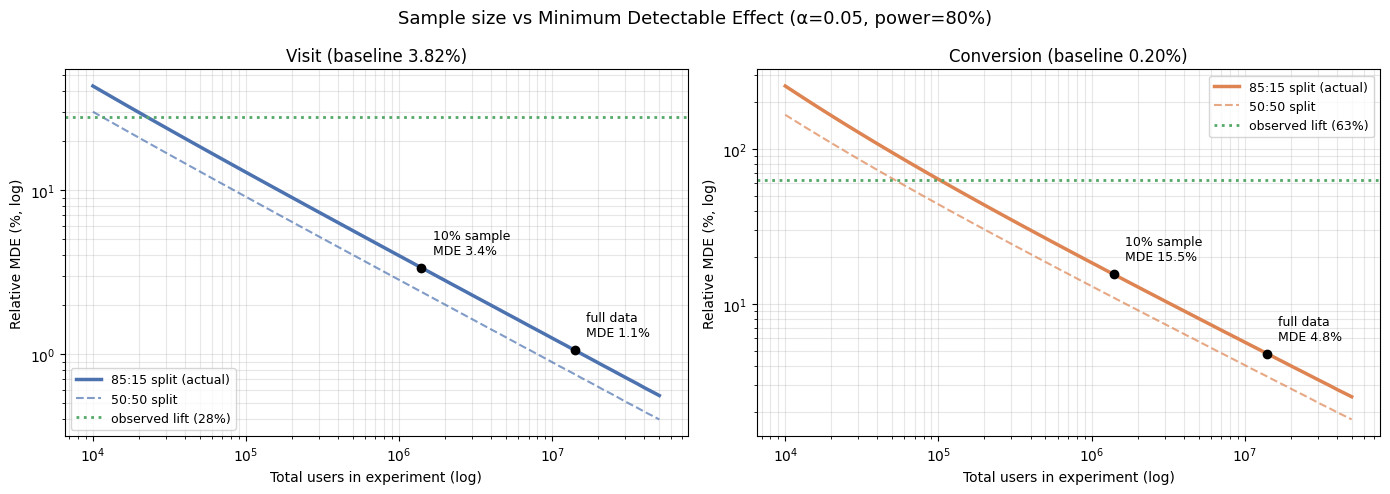

In [7]:
ns = np.logspace(4, np.log10(5e7), 80)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, m, color in [(axes[0], "visit", "#4C72B0"), (axes[1], "conversion", "#DD8452")]:
    mde_rel = [mde_proportion(base[m], int(n * T_SHARE), int(n * (1 - T_SHARE)))["mde_rel"] for n in ns]
    mde_rel_50 = [mde_proportion(base[m], int(n * 0.5), int(n * 0.5))["mde_rel"] for n in ns]
    ax.plot(ns, np.array(mde_rel) * 100, color=color, lw=2.5, label="85:15 split (actual)")
    ax.plot(ns, np.array(mde_rel_50) * 100, color=color, lw=1.5, ls="--", alpha=0.7, label="50:50 split")
    ax.axhline(observed[m] / base[m] * 100, color="#55A868", ls=":", lw=2,
               label=f"observed lift ({observed[m]/base[m]:.0%})")
    for n, lab in [(n_t + n_c, "10% sample"), (FULL_N, "full data")]:
        val = mde_proportion(base[m], int(n * T_SHARE), int(n * (1 - T_SHARE)))["mde_rel"] * 100
        ax.scatter([n], [val], color="black", zorder=5)
        ax.annotate(f"{lab}\nMDE {val:.1f}%", (n, val), textcoords="offset points", xytext=(8, 10), fontsize=9)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Total users in experiment (log)")
    ax.set_ylabel("Relative MDE (%, log)")
    ax.set_title(f"{m.capitalize()} (baseline {base[m]:.2%})")
    ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=9)
fig.suptitle("Sample size vs Minimum Detectable Effect (α=0.05, power=80%)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "04_sample_size_vs_mde.png", dpi=110)
plt.show()

## 5.4 The cost of an 85:15 split

With the same total users, an unequal split is less efficient. Variance ∝ $\frac{1}{n_T} + \frac{1}{n_C}$, which is smallest at 50:50.
The company chose 85:15 because control users see no ads (lost revenue): it traded statistical power for business cost.

In [8]:
alloc = []
for s in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]:
    factor = (1 / s + 1 / (1 - s)) / 4          # variance relative to 50:50
    alloc.append({"treatment share": f"{s:.0%}", "control users": f"{1-s:.0%}",
                  "MDE vs 50:50": np.sqrt(factor), "users needed vs 50:50": factor})
pd.DataFrame(alloc).set_index("treatment share").style.format({"MDE vs 50:50": "{:.2f}x", "users needed vs 50:50": "{:.2f}x"})

,control users,MDE vs 50:50,users needed vs 50:50
treatment share,,,
50%,50%,1.00x,1.00x
60%,40%,1.02x,1.04x
70%,30%,1.09x,1.19x
80%,20%,1.25x,1.56x
85%,15%,1.40x,1.96x
90%,10%,1.67x,2.78x
95%,5%,2.29x,5.26x


## 5.5 Power inside segments (preview for Step 7)

Step 7 splits the data into segments. Each segment is smaller, so the MDE grows (~√k times for k segments).

In [9]:
seg = []
for k in [1, 3, 5, 10]:
    n = (n_t + n_c) / k
    for m in ["visit", "conversion"]:
        r = mde_proportion(base[m], int(n * T_SHARE), int(n * (1 - T_SHARE)))
        seg.append({"segments": k, "metric": m, "users/segment": int(n),
                    "MDE_rel": r["mde_rel"], "observed lift": observed[m] / base[m]})
pd.DataFrame(seg).pivot(index="segments", columns="metric", values="MDE_rel").style.format("{:.1%}")

metric,conversion,visit
segments,,
1,15.5%,3.4%
3,27.6%,5.8%
5,36.2%,7.6%
10,52.9%,10.8%


## 5.6 Why not "observed power"?

Computing power from the observed effect *after* the experiment (post-hoc power) is a common mistake. It is just a transformation
of the p-value and adds no new information. Power analysis belongs at **design time**, for an MDE chosen in advance.
That is why we only compare the observed effect with the MDE above, without computing power from it.

## Summary

In [10]:
print(f"Visit      MDE (10% sample) = {v['MDE_abs (pp)']:.3f} pp ({v['MDE_rel']:.1%} rel) | observed {v['observed ITT (pp)']:.2f} pp = {v['observed / MDE']:.1f}x MDE")
print(f"Conversion MDE (10% sample) = {c['MDE_abs (pp)']:.3f} pp ({c['MDE_rel']:.1%} rel) | observed {c['observed ITT (pp)']:.3f} pp = {c['observed / MDE']:.1f}x MDE")
print(f"10% rel lift needs: visit {r_v:,} users, conversion {r_c:,} users")
print(f"85:15 needs {(1/0.85 + 1/0.15)/4:.2f}x the users of a 50:50 test for the same MDE")

Visit      MDE (10% sample) = 0.128 pp (3.4% rel) | observed 1.07 pp = 8.3x MDE
Conversion MDE (10% sample) = 0.031 pp (15.5% rel) | observed 0.123 pp = 4.0x MDE
10% rel lift needs: visit 162,400 users, conversion 3,281,742 users
85:15 needs 1.96x the users of a 50:50 test for the same MDE


## Key takeaways (Step 5)

1. **Visit:** with the 10% sample (1.4 million users, 85:15) the MDE is **0.13 pp** (3.4% relative), i.e. ~1.3 extra visits per 1,000 users.
   The observed ITT of 1.07 pp is **8.3×** the MDE. The experiment is well powered for visit.
   On the CACE scale (÷ 3.6% exposure) the MDE is ≈ 3.6 pp per exposed user.
2. **Conversion:** MDE = **0.031 pp (15.5% relative)**. The observed lift (+63%) is 4× the MDE, so it was detected.
   If the true effect had been only 10%, the 10% sample would have missed it.
3. **The cost of a rare metric:** detecting the same 10% relative lift needs ~162,000 users for visit but **~3.3 million for conversion (20× more)**.
   A 5% lift on conversion needs ~12.8 million users, almost the whole dataset.
4. **The cost of the 85:15 split:** the same MDE needs **1.96× the users** of a 50:50 test (or, with the same users, a 1.40× larger MDE).
   The company accepted this trade-off on purpose: control users see no ads, so the control group was kept small.
5. **Simulation check:** with the true effect equal to the MDE, power was 80.3% (visit) and 81.7% (conversion). The formula holds.
6. **Warning for Step 7:** with 10 segments, the per-segment MDE grows to ~11% for visit and **~53% for conversion**.
   So segment analysis focuses **on visit**; segment-level conversion results will be noisy.
7. **No post-hoc ("observed") power** was computed, because it is just another form of the p-value and adds no information.